# Phishing URL Detection

This notebook trains and compares several machine learning models for phishing URL detection.

In [1]:
# Import required libraries
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
)

# Suppress tqdm widget warnings in notebooks
os.environ["TQDM_DISABLE"] = "1"
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message=".*IProgress not found.*")

# Use a lightweight tqdm-compatible setup
try:
    from tqdm import tqdm
    tqdm.pandas()
except Exception:
    pass

# Run the full evaluation workflow
FAST_RUN = False


def print_binary_metrics(y_true, y_pred, y_score=None):
    print(classification_report(y_true, y_pred, digits=4))
    cm = confusion_matrix(y_true, y_pred)
    print("Confusion matrix:\n", cm)
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Precision (macro):", precision_score(y_true, y_pred, average="macro", zero_division=0))
    print("Recall (macro):", recall_score(y_true, y_pred, average="macro", zero_division=0))
    print("F1 (macro):", f1_score(y_true, y_pred, average="macro", zero_division=0))
    print("Precision (weighted):", precision_score(y_true, y_pred, average="weighted", zero_division=0))
    print("Recall (weighted):", recall_score(y_true, y_pred, average="weighted", zero_division=0))
    print("F1 (weighted):", f1_score(y_true, y_pred, average="weighted", zero_division=0))
    if y_score is not None:
        try:
            print("ROC-AUC:", roc_auc_score(y_true, y_score))
            print("PR-AUC:", average_precision_score(y_true, y_score))
        except Exception as e:
            print("Could not compute ranking metrics:", e)


def get_probability_score(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    if hasattr(model, "decision_function"):
        return model.decision_function(X)
    raise ValueError(f"Model {model} does not expose predict_proba or decision_function.")


def evaluate_cv_model(name, model, X, y, cv):
    metrics = {
        "accuracy": [],
        "precision_macro": [],
        "recall_macro": [],
        "f1_macro": [],
        "roc_auc": [],
        "pr_auc": [],
    }
    confusion_matrices = []
    for fold_idx, (train_idx, val_idx) in enumerate(cv.split(X, y), start=1):
        X_train_fold, X_val_fold = X.iloc[train_idx], X.iloc[val_idx]
        y_train_fold, y_val_fold = y.iloc[train_idx], y.iloc[val_idx]
        model.fit(X_train_fold, y_train_fold)
        y_pred = model.predict(X_val_fold)
        y_score = get_probability_score(model, X_val_fold)

        metrics["accuracy"].append(accuracy_score(y_val_fold, y_pred))
        metrics["precision_macro"].append(precision_score(y_val_fold, y_pred, average="macro", zero_division=0))
        metrics["recall_macro"].append(recall_score(y_val_fold, y_pred, average="macro", zero_division=0))
        metrics["f1_macro"].append(f1_score(y_val_fold, y_pred, average="macro", zero_division=0))
        metrics["roc_auc"].append(roc_auc_score(y_val_fold, y_score))
        metrics["pr_auc"].append(average_precision_score(y_val_fold, y_score))
        confusion_matrices.append(confusion_matrix(y_val_fold, y_pred))

    print(f"\n{name} cross-validation results:")
    for metric_name, values in metrics.items():
        print(f"  {metric_name}: {np.mean(values):.4f} ± {np.std(values):.4f}")
    for i, cm in enumerate(confusion_matrices, start=1):
        print(f"  fold {i} confusion matrix:\n{cm}")
    return metrics

print("All libraries imported successfully.")

C:\Users\shaje\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All libraries imported successfully.


## Data loading and preprocessing

In [2]:
print("Checking dataset for duplicate rows and feature-based label conflicts...")
raw_df = pd.read_csv("cluster_2_merged.csv")
feature_cols = [col for col in raw_df.columns if col != "label"]

exact_duplicate_count = raw_df.duplicated().sum()
print(f"Exact duplicate rows in raw data: {exact_duplicate_count}")

if exact_duplicate_count > 0:
    df = raw_df.drop_duplicates().reset_index(drop=True)
else:
    df = raw_df.copy()

# Keep contiguous memory layout for later operations.
df = df.copy()

feature_duplicate_count = df.duplicated(subset=feature_cols).sum()
print(f"Duplicate feature vectors after exact deduplication: {feature_duplicate_count}")

conflict_rows = df[df.duplicated(subset=feature_cols, keep=False)].copy()
conflict_rows["feature_hash"] = pd.util.hash_pandas_object(conflict_rows[feature_cols], index=False)

label_counts = conflict_rows.groupby("feature_hash")["label"].nunique()
conflict_hashes = label_counts[label_counts > 1].index
conflict_feature_vectors = int(len(conflict_hashes))

if conflict_feature_vectors > 0:
    print(f"Found {conflict_feature_vectors} ambiguous feature vectors with conflicting labels.")
    ambiguous_rows = conflict_rows[conflict_rows["feature_hash"].isin(conflict_hashes)].index
    print(f"Dropping {len(ambiguous_rows)} ambiguous rows to avoid label leakage.")
    df = df.drop(index=ambiguous_rows).reset_index(drop=True)
else:
    print("No ambiguous feature vectors with multiple labels were found.")

print("Exact duplicates remaining after cleaning:", df.duplicated().sum())

X = df.drop("label", axis=1)
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training shape: {X_train.shape}, Test shape: {X_test.shape}")
print("Using stratified hold-out split for final evaluation after duplicate cleanup.")
print("Label distribution in training set:\n", y_train.value_counts(normalize=True))
print("Label distribution in test set:\n", y_test.value_counts(normalize=True))

Checking dataset for duplicate rows and feature-based label conflicts...
Exact duplicate rows in raw data: 60083
Duplicate feature vectors after exact deduplication: 6
Found 6 ambiguous feature vectors with conflicting labels.
Dropping 12 ambiguous rows to avoid label leakage.
Exact duplicates remaining after cleaning: 0
Training shape: (69757, 111), Test shape: (17440, 111)
Using stratified hold-out split for final evaluation after duplicate cleanup.
Label distribution in training set:
 label
0    0.650315
1    0.349685
Name: proportion, dtype: float64
Label distribution in test set:
 label
0    0.650344
1    0.349656
Name: proportion, dtype: float64


In [3]:
# Feature extraction helper for raw URLs
from urllib.parse import urlparse
import re

FEATURE_COLUMNS = X.columns.tolist()

# This function creates a feature vector in the exact order used during training.
# Some features require external lookups or network-based domain analysis and are
# currently filled with placeholder values. To deploy a real web interface, add
# the missing external feature extraction logic here.
def extract_url_features(url: str) -> pd.DataFrame:
    parsed = urlparse(url)
    domain = parsed.netloc or ""
    path = parsed.path or ""
    query = parsed.query or ""
    file_name = path.split("/")[-1] if path else ""
    directory = "/".join(path.split("/")[1:-1]) if "/" in path else ""

    def count_char(text: str, char: str) -> int:
        return text.count(char) if isinstance(text, str) else 0

    features = {
        "qty_dot_url": count_char(url, "."),
        "qty_hyphen_url": count_char(url, "-"),
        "qty_underline_url": count_char(url, "_"),
        "qty_slash_url": count_char(url, "/"),
        "qty_questionmark_url": count_char(url, "?"),
        "qty_equal_url": count_char(url, "="),
        "qty_at_url": count_char(url, "@"),
        "qty_and_url": count_char(url, "&"),
        "qty_exclamation_url": count_char(url, "!"),
        "qty_space_url": count_char(url, " "),
        "qty_tilde_url": count_char(url, "~"),
        "qty_comma_url": count_char(url, ","),
        "qty_plus_url": count_char(url, "+"),
        "qty_asterisk_url": count_char(url, "*"),
        "qty_hashtag_url": count_char(url, "#"),
        "qty_dollar_url": count_char(url, "$"),
        "qty_percent_url": count_char(url, "%"),
        "qty_tld_url": len([part for part in domain.split(".") if part]) - 1 if domain else 0,
        "length_url": len(url),
        "qty_dot_domain": count_char(domain, "."),
        "qty_hyphen_domain": count_char(domain, "-"),
        "qty_underline_domain": count_char(domain, "_"),
        "qty_slash_domain": count_char(domain, "/"),
        "qty_questionmark_domain": count_char(domain, "?"),
        "qty_equal_domain": count_char(domain, "="),
        "qty_at_domain": count_char(domain, "@"),
        "qty_and_domain": count_char(domain, "&"),
        "qty_exclamation_domain": count_char(domain, "!"),
        "qty_space_domain": count_char(domain, " "),
        "qty_tilde_domain": count_char(domain, "~"),
        "qty_comma_domain": count_char(domain, ","),
        "qty_plus_domain": count_char(domain, "+"),
        "qty_asterisk_domain": count_char(domain, "*"),
        "qty_hashtag_domain": count_char(domain, "#"),
        "qty_dollar_domain": count_char(domain, "$"),
        "qty_percent_domain": count_char(domain, "%"),
        "qty_vowels_domain": sum(domain.lower().count(v) for v in "aeiou"),
        "domain_length": len(domain),
        "domain_in_ip": int(bool(re.fullmatch(r"[0-9.]+", domain))),
        "server_client_domain": 0,
        "qty_dot_directory": count_char(directory, "."),
        "qty_hyphen_directory": count_char(directory, "-"),
        "qty_underline_directory": count_char(directory, "_"),
        "qty_slash_directory": count_char(directory, "/"),
        "qty_questionmark_directory": count_char(directory, "?"),
        "qty_equal_directory": count_char(directory, "="),
        "qty_at_directory": count_char(directory, "@"),
        "qty_and_directory": count_char(directory, "&"),
        "qty_exclamation_directory": count_char(directory, "!"),
        "qty_space_directory": count_char(directory, " "),
        "qty_tilde_directory": count_char(directory, "~"),
        "qty_comma_directory": count_char(directory, ","),
        "qty_plus_directory": count_char(directory, "+"),
        "qty_asterisk_directory": count_char(directory, "*"),
        "qty_hashtag_directory": count_char(directory, "#"),
        "qty_dollar_directory": count_char(directory, "$"),
        "qty_percent_directory": count_char(directory, "%"),
        "directory_length": len(directory),
        "qty_dot_file": count_char(file_name, "."),
        "qty_hyphen_file": count_char(file_name, "-"),
        "qty_underline_file": count_char(file_name, "_"),
        "qty_slash_file": count_char(file_name, "/"),
        "qty_questionmark_file": count_char(file_name, "?"),
        "qty_equal_file": count_char(file_name, "="),
        "qty_at_file": count_char(file_name, "@"),
        "qty_and_file": count_char(file_name, "&"),
        "qty_exclamation_file": count_char(file_name, "!"),
        "qty_space_file": count_char(file_name, " "),
        "qty_tilde_file": count_char(file_name, "~"),
        "qty_comma_file": count_char(file_name, ","),
        "qty_plus_file": count_char(file_name, "+"),
        "qty_asterisk_file": count_char(file_name, "*"),
        "qty_hashtag_file": count_char(file_name, "#"),
        "qty_dollar_file": count_char(file_name, "$"),
        "qty_percent_file": count_char(file_name, "%"),
        "file_length": len(file_name),
        "qty_dot_params": count_char(query, "."),
        "qty_hyphen_params": count_char(query, "-"),
        "qty_underline_params": count_char(query, "_"),
        "qty_slash_params": count_char(query, "/"),
        "qty_questionmark_params": count_char(query, "?"),
        "qty_equal_params": count_char(query, "="),
        "qty_at_params": count_char(query, "@"),
        "qty_and_params": count_char(query, "&"),
        "qty_exclamation_params": count_char(query, "!"),
        "qty_space_params": count_char(query, " "),
        "qty_tilde_params": count_char(query, "~"),
        "qty_comma_params": count_char(query, ","),
        "qty_plus_params": count_char(query, "+"),
        "qty_asterisk_params": count_char(query, "*"),
        "qty_hashtag_params": count_char(query, "#"),
        "qty_dollar_params": count_char(query, "$"),
        "qty_percent_params": count_char(query, "%"),
        "params_length": len(query),
        "tld_present_params": int("." in query),
        "qty_params": len(query.split("&")) if query else 0,
        "email_in_url": int(bool(re.search(r"[\w\.-]+@[\w\.-]+", url))),
        "time_response": -1,
        "domain_spf": -1,
        "asn_ip": -1,
        "time_domain_activation": -1,
        "time_domain_expiration": -1,
        "qty_ip_resolved": -1,
        "qty_nameservers": -1,
        "qty_mx_servers": -1,
        "ttl_hostname": -1,
        "tls_ssl_certificate": -1,
        "qty_redirects": -1,
        "url_google_index": -1,
        "domain_google_index": -1,
        "url_shortened": int("bit.ly" in url or "tinyurl" in url or "goo.gl" in url),
    }

    # Ensure all expected columns exist and are in the correct order.
    for col in FEATURE_COLUMNS:
        if col not in features:
            features[col] = -1

    return pd.DataFrame([features], columns=FEATURE_COLUMNS)

# Example: convert a single raw URL to the same feature order as training.
example_url = "http://example.com/path?query=1"
print("Example extracted feature vector shape:", extract_url_features(example_url).shape)


Example extracted feature vector shape: (1, 111)


## Model training and evaluation

In [4]:
print("\n" + "=" * 40)
print("1. LOGISTIC REGRESSION (BASELINE)")
print("=" * 40)

lr_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42))
lr_model.fit(X_train, y_train)
lr_predictions = lr_model.predict(X_test)
print_binary_metrics(y_test, lr_predictions, lr_model.predict_proba(X_test)[:, 1])


1. LOGISTIC REGRESSION (BASELINE)
              precision    recall  f1-score   support

           0     0.9550    0.9430    0.9489     11342
           1     0.8963    0.9173    0.9067      6098

    accuracy                         0.9340     17440
   macro avg     0.9257    0.9302    0.9278     17440
weighted avg     0.9345    0.9340    0.9342     17440

Confusion matrix:
 [[10695   647]
 [  504  5594]]
Accuracy: 0.9340022935779817
Precision (macro): 0.9256633490077305
Recall (macro): 0.9301526689302493
F1 (macro): 0.9278280132045559
Precision (weighted): 0.9344833218448416
Recall (weighted): 0.9340022935779817
F1 (weighted): 0.9341753816182482
ROC-AUC: 0.9789059596102663
PR-AUC: 0.9600394404496243


In [5]:
print("\n" + "=" * 40)
print("2. SUPPORT VECTOR MACHINE (SVM)")
print("=" * 40)

svm_model = make_pipeline(StandardScaler(), LinearSVC(max_iter=5000, random_state=42))
svm_model.fit(X_train, y_train)
svm_predictions = svm_model.predict(X_test)
print_binary_metrics(y_test, svm_predictions, svm_model.decision_function(X_test))


2. SUPPORT VECTOR MACHINE (SVM)
              precision    recall  f1-score   support

           0     0.9574    0.9393    0.9482     11342
           1     0.8909    0.9223    0.9063      6098

    accuracy                         0.9333     17440
   macro avg     0.9241    0.9308    0.9273     17440
weighted avg     0.9341    0.9333    0.9336     17440

Confusion matrix:
 [[10653   689]
 [  474  5624]]
Accuracy: 0.9333142201834862
Precision (macro): 0.9241305232899182
Recall (macro): 0.9307609665188219
F1 (macro): 0.9272663009118403
Precision (weighted): 0.9341345337822055
Recall (weighted): 0.9333142201834862
F1 (weighted): 0.9335727810590885
ROC-AUC: 0.9788243848100493
PR-AUC: 0.9600111110115103


In [6]:
print("\n" + "=" * 40)
print("3. RANDOM FOREST CLASSIFIER")
print("=" * 40)

rf_model = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)
print_binary_metrics(y_test, rf_predictions, rf_model.predict_proba(X_test)[:, 1])


3. RANDOM FOREST CLASSIFIER
              precision    recall  f1-score   support

           0     0.9775    0.9765    0.9770     11342
           1     0.9563    0.9582    0.9572      6098

    accuracy                         0.9701     17440
   macro avg     0.9669    0.9673    0.9671     17440
weighted avg     0.9701    0.9701    0.9701     17440

Confusion matrix:
 [[11075   267]
 [  255  5843]]
Accuracy: 0.9700688073394496
Precision (macro): 0.9668972630344248
Recall (macro): 0.9673210945493286
F1 (macro): 0.9671085794939006
Precision (weighted): 0.9700833891523463
Recall (weighted): 0.9700688073394496
F1 (weighted): 0.9700755968528567
ROC-AUC: 0.9946065928747753
PR-AUC: 0.9907256002845973


In [7]:
print("\n" + "=" * 40)
print("4. XGBOOST CLASSIFIER")
print("=" * 40)

xgb_model = make_pipeline(StandardScaler(), XGBClassifier(
    eval_metric="logloss",
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
))
xgb_model.fit(X_train, y_train)
xgb_predictions = xgb_model.predict(X_test)
print_binary_metrics(y_test, xgb_predictions, xgb_model.predict_proba(X_test)[:, 1])


4. XGBOOST CLASSIFIER
              precision    recall  f1-score   support

           0     0.9759    0.9746    0.9753     11342
           1     0.9529    0.9552    0.9541      6098

    accuracy                         0.9678     17440
   macro avg     0.9644    0.9649    0.9647     17440
weighted avg     0.9679    0.9678    0.9678     17440

Confusion matrix:
 [[11054   288]
 [  273  5825]]
Accuracy: 0.9678325688073395
Precision (macro): 0.9643927927449647
Recall (macro): 0.964919438161588
F1 (macro): 0.9646551821272494
Precision (weighted): 0.9678523603842231
Recall (weighted): 0.9678325688073395
F1 (weighted): 0.9678416835138229
ROC-AUC: 0.9943962363047014
PR-AUC: 0.9901045347243138


## Explainability with SHAP

SHAP (SHapley Additive exPlanations) is a method used to explain machine learning predictions. It shows how much each feature contributes to a model's decision, helping us understand which URL characteristics influence whether a sample is classified as phishing.


PHASE 3: GENERATING SHAP EXPLANATIONS

Rendering SHAP bar summary plot for 300 samples...


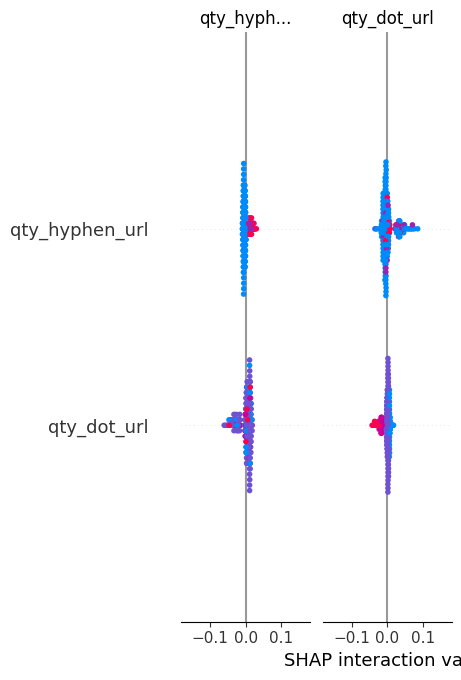

In [8]:
print("\n" + "=" * 40)
print("PHASE 3: GENERATING SHAP EXPLANATIONS")
print("=" * 40)

# Use a small but representative subset for faster SHAP generation
shap_sample_size = 300
X_test_sample = X_test.sample(min(shap_sample_size, len(X_test)), random_state=42)

# Prefer the final model if it exists; otherwise use the trained Random Forest model
model_to_explain = globals().get("final_model") or globals().get("rf_model") or globals().get("xgb_model")

if model_to_explain is None:
    raise RuntimeError("No trained model available for SHAP explanation. Run the model training cells first.")

if hasattr(model_to_explain, "named_steps"):
    final_estimator = model_to_explain.named_steps[model_to_explain.steps[-1][0]]
else:
    final_estimator = model_to_explain

if isinstance(final_estimator, (RandomForestClassifier, XGBClassifier)):
    explainer = shap.TreeExplainer(final_estimator)
    shap_values = explainer.shap_values(X_test_sample)

    if isinstance(shap_values, list) and len(shap_values) == 2:
        # For binary classifiers, use the SHAP values for the positive class
        shap_values = shap_values[1]

    shap_values = np.asarray(shap_values)

    print(f"\nRendering SHAP bar summary plot for {len(X_test_sample)} samples...")
shap.summary_plot(shap_values, X_test_sample, plot_type="bar")